In [1]:
# 06_evaluation.ipynb 
# Benchmark Evaluation and System Analysis 

In [3]:
import json 
from pathlib import Path 
import pandas as pd 
import matplotlib.pyplot as plt 

PROJECT_ROOT = Path("..").resolve() 
EVAL_DIR = PROJECT_ROOT / "data" / "evaluation" 

BENCHMARK_RESULTS_JSON = EVAL_DIR / "benchmark_results.json" 
BENCHMARK_RESULTS_CSV = EVAL_DIR / "benchmark_results.csv" 
BENCHMARK_SUMMARY_JSON = EVAL_DIR / "benchmark_summary.json" 

# Load outputs 
def load_json(path): 
    # Indented 4 spaces
    with open(path, "r", encoding="utf-8") as f: 
        # Indented an additional 4 spaces (nested inside 'with')
        return json.load(f) 

# Script execution continues out of the function block
benchmark_results = load_json(BENCHMARK_RESULTS_JSON) 
benchmark_summary = load_json(BENCHMARK_SUMMARY_JSON) 
benchmark_df = pd.read_csv(BENCHMARK_RESULTS_CSV) 

print("Benchmark queries:", len(benchmark_results)) 
print(benchmark_df.head())

Benchmark queries: 45
               query_id                                           question  \
0  cbe_apps_cbebirr_001                ሲቢኢ ብር (CBEBirr) ምን ዓይነት አገልግሎት ነው?   
1  cbe_apps_cbebirr_002  ሲቢኢ ብር (CBEBirr) በተለይ ለማን ወይም ለየትኛው አካባቢ የተሰራ ነው?   
2  cbe_apps_cbebirr_003  የሲቢኢ ብር (CBEBirr) ከባህላዊ የባንክ አገልግሎት የሚለየው ዋና ጥ...   
3  cbe_apps_cbebirr_004                ፋስት ፔይ (fastPAY) ምን ዓይነት መተግበሪያ ነው?   
4  cbe_apps_cbebirr_005  የፋስት ፔይ (fastPAY) ተጠቃሚዎች የፋይናንስ እንቅስቃሴያቸውን በምን...   

  difficulty       query_type retrieval_mode complexity_label  \
0        low       definition          dense           medium   
1     medium  target_audience          dense           medium   
2       high       comparison          dense           medium   
3        low       definition          dense           medium   
4       high        objective          dense           medium   

   complexity_score  exact_match  token_f1  keyword_coverage  ...  \
0            0.3600          0.0  0.066667       

In [4]:
#Overall summary 
benchmark_summary 

{'num_queries': 45,
 'retrieval_metrics': {'recall@1': 0.0,
  'recall@3': 0.0,
  'recall@5': 0.0,
  'precision@1': 0.0,
  'precision@3': 0.0,
  'precision@5': 0.0,
  'hit@1': 0.0,
  'hit@3': 0.0,
  'hit@5': 0.0,
  'mrr': 0.0},
 'answer_metrics': {'exact_match': 0.0,
  'token_f1': 0.05685,
  'keyword_coverage': 0.044444,
  'reference_overlap': 0.032395},
 'trust_metrics': {'avg_grounding_overlap': 0.855604,
  'avg_trust_score': 0.855604,
  'avg_citation_count': 1.044444,
  'high_trust_count': 45,
  'medium_trust_count': 0,
  'low_trust_count': 0,
  'insufficient_evidence_count': 0},
 'timing': {'avg_retrieval_sec': 0.132156,
  'avg_rerank_sec': 0.002111,
  'avg_prompt_sec': 0.000222,
  'avg_generation_sec': 249.553356,
  'avg_validation_sec': 0.001289,
  'avg_total_sec': 249.692156},
 'by_retrieval_mode': {'dense': {'count': 37,
   'token_f1': 0.040991,
   'recall@5': 0.0,
   'avg_trust_score': 0.850016,
   'avg_total_sec': 113.800784},
  'hybrid': {'count': 7,
   'token_f1': 0.140139,


In [5]:
#Retrieval metrics summary 
pd.DataFrame([benchmark_summary["retrieval_metrics"]])

,recall@1,recall@3,recall@5,precision@1,precision@3,precision@5,hit@1,hit@3,hit@5,mrr
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
# Answer metrics summary 
pd.DataFrame([benchmark_summary["answer_metrics"]]) 

,exact_match,token_f1,keyword_coverage,reference_overlap
0,0.0,0.05685,0.044444,0.032395


In [7]:
#Trust metrics summary 
pd.DataFrame([benchmark_summary["trust_metrics"]]) 

,avg_grounding_overlap,avg_trust_score,avg_citation_count,high_trust_count,medium_trust_count,low_trust_count,insufficient_evidence_count
0,0.855604,0.855604,1.044444,45,0,0,0


In [8]:
#Trust label distribution 
benchmark_df["trust_label"].value_counts() 

trust_label
high    45
Name: count, dtype: int64

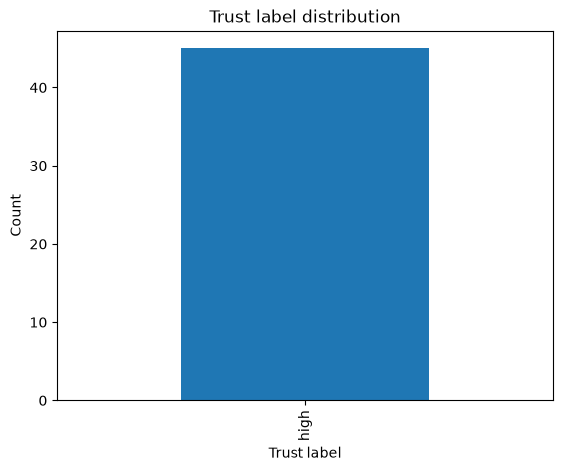

In [9]:
#Plot trust label distribution 
benchmark_df["trust_label"].value_counts().plot(kind="bar") 
plt.title("Trust label distribution") 
plt.xlabel("Trust label") 
plt.ylabel("Count") 
plt.show() 

In [10]:
#Retrieval mode performance 
mode_perf = benchmark_df.groupby("retrieval_mode")[[ 
"token_f1", 
"recall@5", 
"trust_score" 
]].mean().reset_index() 
mode_perf

,retrieval_mode,token_f1,recall@5,trust_score
0,dense,0.040991,0.0,0.850016
1,hybrid,0.140139,0.0,0.881319
2,sparse,0.060606,0.0,0.882353


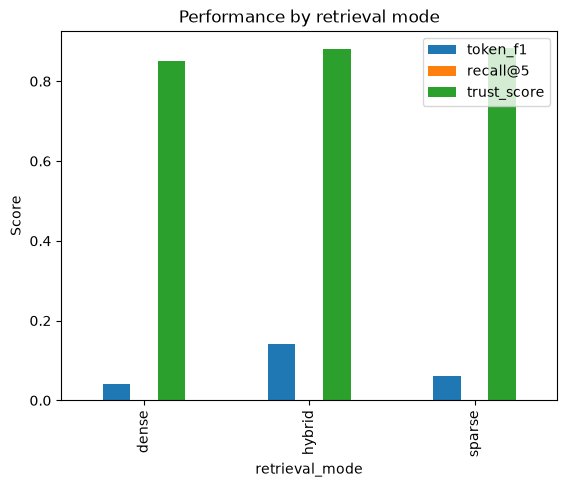

In [11]:
# Plot retrieval mode comparison 
mode_perf.set_index("retrieval_mode")[["token_f1", "recall@5", 
"trust_score"]].plot(kind="bar") 
plt.title("Performance by retrieval mode") 
plt.ylabel("Score") 
plt.show()

In [12]:
#Difficulty-level performance 
difficulty_perf = benchmark_df.groupby("difficulty")[[ 
"token_f1", 
"recall@5", 
"trust_score" 
]].mean().reset_index() 
difficulty_perf 

,difficulty,token_f1,recall@5,trust_score
0,high,0.038335,0.0,0.848368
1,low,0.082794,0.0,0.863741
2,medium,0.043492,0.0,0.852652


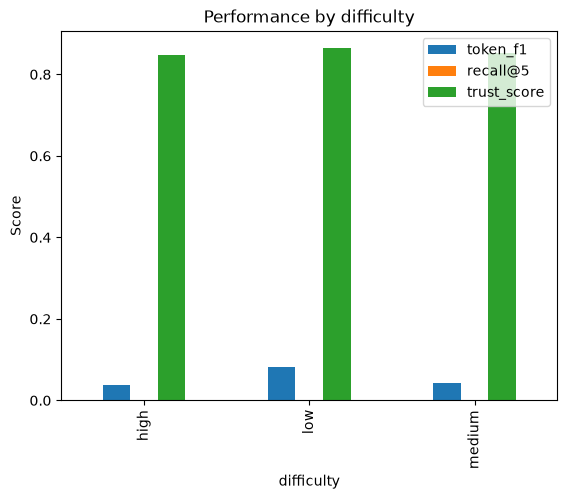

In [13]:
# Plot difficulty-level comparison 
difficulty_perf.set_index("difficulty")[["token_f1", "recall@5", "trust_score"]].plot(kind="bar") 
plt.title("Performance by difficulty") 
plt.ylabel("Score") 
plt.show() 

In [14]:
#Complexity-level performance 
complexity_perf = benchmark_df.groupby("complexity_label")[[ 
"token_f1", 
"recall@5", 
"trust_score" 
]].mean().reset_index() 
complexity_perf 

,complexity_label,token_f1,recall@5,trust_score
0,low,0.060606,0.0,0.882353
1,medium,0.056764,0.0,0.854996


In [ ]:
# Scatter: trust score vs token F1 
benchmark_df.plot.scatter(x="token_f1", y="trust_score") 
plt.title("Trust score vs token F1") 
plt.show() 

In [15]:
# Lowest-performing queries 
benchmark_df.sort_values("token_f1").head(10)

,query_id,question,difficulty,query_type,retrieval_mode,complexity_label,complexity_score,exact_match,token_f1,keyword_coverage,...,citation_count,grounding_overlap,trust_score,trust_label,t_retrieval,t_rerank,t_prompt,t_generation,t_validation,t_total
1,cbe_apps_cbebirr_002,ሲቢኢ ብር (CBEBirr) በተለይ ለማን ወይም ለየትኛው አካባቢ የተሰራ ነው?,medium,target_audience,dense,medium,0.3900,0.0,0.0,0.0,...,1,0.921053,0.921053,high,0.034,0.001,0.000,51.001,0.001,51.039
5,cbe_apps_cbebirr_006,ካሽ ጎ (CashGo) ምን ዓይነት መተግበሪያ ነው?,low,definition,dense,medium,0.3514,0.0,0.0,0.0,...,1,0.777778,0.777778,high,0.038,0.001,0.001,135.435,0.001,135.479
6,cbe_apps_cbebirr_007,የካሽ ጎ (CashGo) ተጠቃሚዎች የገንዘብ ጉዳዮቻቸውን እንዴት እንዲያከ...,medium,procedure,hybrid,medium,0.4745,0.0,0.0,0.0,...,1,1.000000,1.000000,high,0.203,0.003,0.000,116.126,0.000,116.337
11,cbe_apps_cbebirr_012,Merchant App ምን ዓይነት መተግበሪያ ነው?,low,definition,dense,medium,0.3633,0.0,0.0,0.0,...,1,0.947368,0.947368,high,0.060,0.001,0.000,123.195,0.001,123.259
10,cbe_apps_cbebirr_011,የነዳጅ መተግበሪያ (Fuel App / Fuel Pay) ተጠቃሚዎች ምን ሳይ...,medium,procedure,dense,medium,0.4467,0.0,0.0,0.0,...,1,0.750000,0.750000,high,0.132,0.003,0.000,89.340,0.000,89.477
14,cbe_docs_002,በCBE Docs ተጠቃሚዎች ወደ የኢትዮጵያ ንግድ ባንክ ቅርንጫፍ ሳይሄዱ ...,low,procedure,dense,medium,0.4129,0.0,0.0,0.0,...,1,1.000000,1.000000,high,0.108,0.003,0.000,102.911,0.001,103.024
18,cbe_docs_006,በCBE Docs ውስጥ ኢ-ፊርማ (E-signature) ሲጠቀሙ ሰነዶች ምን...,medium,procedure,dense,medium,0.4338,0.0,0.0,0.0,...,1,1.000000,1.000000,high,0.214,0.002,0.000,122.488,0.001,122.709
17,cbe_docs_005,CBE Docs የቅጾች መሙላት እና ማስገባት ሂደት ከስህተት እንዲጸዳ ምን...,medium,procedure,dense,medium,0.3862,0.0,0.0,0.0,...,1,0.888889,0.888889,high,0.062,0.002,0.000,123.641,0.001,123.710
22,cbe_docs_010,CBE Docs ለምን ፈጣን እና ቀልጣፋ ተብሎ ይገለጻል?,medium,causal,dense,medium,0.3500,0.0,0.0,0.0,...,1,0.952381,0.952381,high,0.132,0.002,0.000,147.064,0.003,147.202
19,cbe_docs_007,CBE Docs በሰነድ ፊርማ ሂደት ውስጥ አንድ ሰው ብቻ ሳይሆን ብዙ ሰዎ...,high,causal,dense,medium,0.4522,0.0,0.0,0.0,...,1,1.000000,1.000000,high,0.132,0.003,0.001,122.012,0.001,122.151


In [16]:
#Low-trust cases 
benchmark_df[benchmark_df["trust_label"].isin(["low", "insufficient_evidence"])].head(10)

,query_id,question,difficulty,query_type,retrieval_mode,complexity_label,complexity_score,exact_match,token_f1,keyword_coverage,...,citation_count,grounding_overlap,trust_score,trust_label,t_retrieval,t_rerank,t_prompt,t_generation,t_validation,t_total


In [18]:
# Inspect one failed example in detail 
failed = benchmark_results[0] 

# Choose a failed example manually if needed 
for rec in benchmark_results: 
    if rec["validation"]["trust_label"] in ["low", "insufficient_evidence"]: 
        failed = rec 
        break 

print("QUERY ID:", failed["query_id"]) 
print("QUESTION:", failed["question"]) 
print("RETRIEVAL MODE:", failed["retrieval_mode"]) 
print("DIFFICULTY:", failed["difficulty"]) 
print("QUERY TYPE:", failed["query_type"]) 
 
print("\nGENERATED ANSWER:") 
print(failed["generation"]["answer"]) 
 
print("\nANSWER METRICS:") 
print(failed["answer_metrics"]) 
 
print("\nTRUST VALIDATION:") 
print(failed["validation"])

QUERY ID: cbe_apps_cbebirr_001
QUESTION: ሲቢኢ ብር (CBEBirr) ምን ዓይነት አገልግሎት ነው?
RETRIEVAL MODE: dense
DIFFICULTY: low
QUERY TYPE: definition

GENERATED ANSWER:
CBE Docs የሚገባው ሲሆን በአሰራር ሂደቶች እና ፈጣን አገልግሎት የባንክ ጉዳዮችዎን በጥቂት ደቂቃዎች ውስጥ ያጠናቅቁ።

ANSWER METRICS:
{'exact_match': 0.0, 'token_f1': 0.066667, 'keyword_coverage': 0.333333, 'reference_overlap': 0.034483}

TRUST VALIDATION:
{'citation_count': 1, 'citation_ok': True, 'grounding_overlap': 0.8, 'unsupported_penalty': 0.0, 'trust_score': 0.8, 'trust_label': 'high'}


In [19]:
#Retrieved evidence for failed example
for i, item in enumerate(failed["retrieved_chunks"][:3], start=1): 
    print("=" * 80) 
    print("Rank:", i) 
    print("Chunk ID:", item["chunk_id"]) 
    print("Score:", item["score"]) 
    print("Source:", item["metadata"]["source_file"]) 
    print("-" * 80) 
    print(item["text"][:1500]) 
    print()

Rank: 1
Chunk ID: chunk_000982
Score: 0.396991
Source: cleaned28_የኢትዮጵያ ንግድ ባንክ በቁጥር.txt
--------------------------------------------------------------------------------
ይገኛሉ። በተጨማሪም የሲቢኢ ብር (CBE Birr) ዲጂታል የክፍያና የገንዘብ ዝውውር መድረክ ከ30.4 ሚሊዮን በላይ ተጠቃሚዎችን በማገልገል በኢትዮጵያ ትልቁ ዲጂታል የፋይናንስ ሥርኣት ሆኖ ቀጥሏል። ባንኩ ከወለድ ነፃ የባንክ አገልግሎት (CBE Noor) ተደራሽነትን ለማስፋት 155 ልዩ የሲቢኢ ኑር ቅርንጫፎችን በመክፈት የሸሪኣ መርሆዎችን የሚከተል የፋይናንስ አገልግሎት ለሚፈልጉ ደንበኞች ተደራሽ አድርጎታል። እነዚህ አሃዞች የኢትዮጵያ ንግድ ባንክ በደንበኞች ብዛት፣ በአገልግሎት ተደራሽነት፣ በዲጂታል ባንኪንግ እና በፋይናንስ ማካተት ዘርፍ ያለውን ጠንካራ አቋም በግልፅ ያሳያሉ።

Rank: 2
Chunk ID: chunk_000981
Score: 0.392518
Source: cleaned28_የኢትዮጵያ ንግድ ባንክ በቁጥር.txt
--------------------------------------------------------------------------------
የኢትዮጵያ ንግድ ባንክ (CBE) በአገራችን የባንክ ዘርፍ ውስጥ የመሪነት ሚናውን በማስቀጠል በስፋት የተደራጀ የአገልግሎት አውታረ መረብ እና ዘመናዊ ዲጂታል የፋይናንስ ስርኣት ያለው ተቋም ነው። ባንኩ በመላው ኢትዮጵያ ከ1,971 በላይ ቅርንጫፎችና የአገልግሎት መስጫ ጣቢያዎችን በማስፋፋት ለዜጎች ተደራሽ የባንክ አገልግሎት እየሰጠ ይገኛል። በአሁኑ ወቅት የባንኩ ጠቅላላ የደንበኞች ቁጥር ከ45.87 ሚሊዮን በላይ የደረሰ ሲሆን፣ ይህም የህብረተሰቡ በባንኩ

In [20]:
# Paper-ready benchmark table 
paper_table = benchmark_df.groupby("retrieval_mode")[[ 
    "recall@5", 
    "token_f1", 
    "trust_score" 
]].mean().round(3) 
 
paper_table 

,recall@5,token_f1,trust_score
retrieval_mode,,,
dense,0.0,0.041,0.850
hybrid,0.0,0.140,0.881
sparse,0.0,0.061,0.882
